# Experiment 6: Variational Autoencoders (VAEs) for Image Generation

**Aim:** Implement a convolutional Variational Autoencoder in TensorFlow/Keras, train it on MNIST, and use it to
reconstruct, generate and interpolate images and to explore a 2-D latent space.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(3)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")[..., None]; x_test = (x_test / 255.0).astype("float32")[..., None]
print("train", x_train.shape, "test", x_test.shape, "| pixel range [0,1] (Bernoulli decoder)")

I0000 00:00:1792689074.737286    2905 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792689076.717676    2905 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


train (60000, 28, 28, 1) test (10000, 28, 28, 1) | pixel range [0,1] (Bernoulli decoder)


## 1. Model
The **encoder** outputs the mean $\mu$ and log-variance $\log\sigma^2$ of $q_\phi(z|x)$. Sampling uses the
**reparameterisation trick** $z=\mu+\sigma\odot\epsilon,\ \epsilon\sim\mathcal{N}(0,I)$, which keeps the sampling step
differentiable. The **decoder** maps $z$ back to an image. The loss is the negative ELBO:
$$\mathcal{L}=\underbrace{\mathrm{BCE}(x,\hat x)}_{\text{reconstruction}}+\beta\,\underbrace{\mathrm{KL}\big(q(z|x)\,\|\,\mathcal{N}(0,I)\big)}_{\text{regulariser}}$$

In [2]:
class Sampling(layers.Layer):
    def call(self, inputs):
        mu, logvar = inputs
        return mu + tf.exp(0.5 * logvar) * tf.random.normal(tf.shape(mu))

def build_encoder(latent):
    inp = keras.Input((28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Flatten()(x); x = layers.Dense(128, activation="relu")(x)
    mu, logvar = layers.Dense(latent, name="mu")(x), layers.Dense(latent, name="logvar")(x)
    return keras.Model(inp, [mu, logvar, Sampling()([mu, logvar])], name="encoder")

def build_decoder(latent):
    inp = keras.Input((latent,))
    x = layers.Dense(7 * 7 * 64, activation="relu")(inp); x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
    return keras.Model(inp, layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(x), name="decoder")

class VAE(keras.Model):
    def __init__(self, latent, beta=1.0):
        super().__init__()
        self.enc, self.dec, self.beta = build_encoder(latent), build_decoder(latent), beta
        self.trk = {k: keras.metrics.Mean(name=k) for k in ("loss", "recon", "kl")}
    @property
    def metrics(self): return list(self.trk.values())
    def train_step(self, x):
        with tf.GradientTape() as tape:
            mu, logvar, z = self.enc(x, training=True)
            rec = self.dec(z, training=True)
            recon = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, rec), axis=(1, 2)))
            kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
            loss = recon + self.beta * kl
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_weights), self.trainable_weights))
        for k, v in zip(("loss", "recon", "kl"), (loss, recon, kl)): self.trk[k].update_state(v)
        return {k: m.result() for k, m in self.trk.items()}

vae16 = VAE(16)
vae16.enc.summary(print_fn=print); vae16.dec.summary(print_fn=print)

Model: "encoder"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───

Model: "decoder"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     

In [3]:
vae16.compile(optimizer=keras.optimizers.Adam(1e-3))
h16 = vae16.fit(x_train, epochs=15, batch_size=128, verbose=2)

Epoch 1/15


469/469 - 38s - 81ms/step - kl: 11.3589 - loss: 182.3420 - recon: 170.9830


Epoch 2/15


469/469 - 38s - 81ms/step - kl: 20.2216 - loss: 118.8186 - recon: 98.5968


Epoch 3/15


469/469 - 41s - 87ms/step - kl: 20.9167 - loss: 110.0143 - recon: 89.0976


... (20 outputs left out)

Epoch 14/15


469/469 - 33s - 70ms/step - kl: 22.6635 - loss: 99.5455 - recon: 76.8821


Epoch 15/15


469/469 - 32s - 68ms/step - kl: 22.6684 - loss: 99.3107 - recon: 76.6423


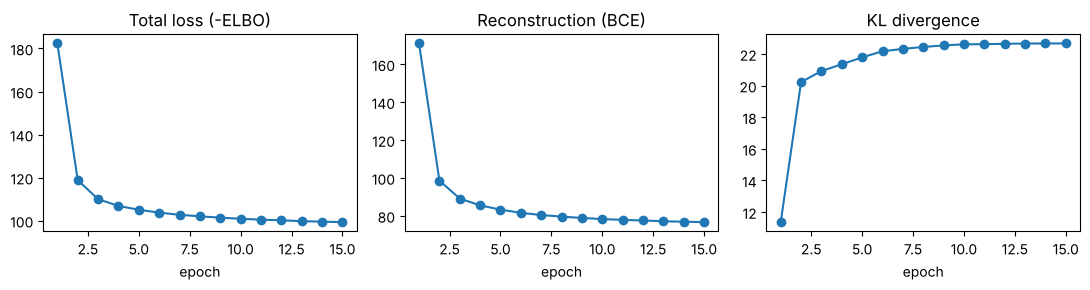

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, k, t in zip(ax, ("loss", "recon", "kl"), ("Total loss (-ELBO)", "Reconstruction (BCE)", "KL divergence")):
    a.plot(range(1, 16), h16.history[k], "o-"); a.set_title(t); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 2. Reconstruction, generation and interpolation

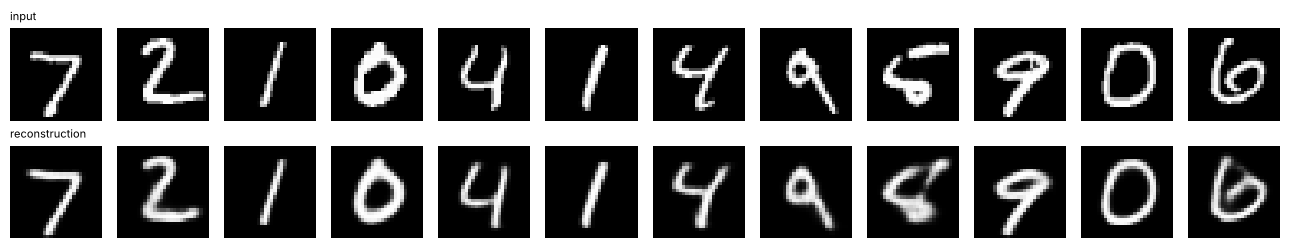

Test reconstruction MSE (2000 images): 0.00922


In [5]:
mu, _, _ = vae16.enc(x_test[:12], training=False)
rec = vae16.dec(mu).numpy()
fig, axes = plt.subplots(2, 12, figsize=(13, 2.6))
for i in range(12):
    axes[0, i].imshow(x_test[i, ..., 0], cmap="gray"); axes[1, i].imshow(rec[i, ..., 0], cmap="gray")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_title("input", fontsize=8, loc="left"); axes[1, 0].set_title("reconstruction", fontsize=8, loc="left")
plt.tight_layout(); plt.show()
mse = float(np.mean((vae16.dec(vae16.enc(x_test[:2000])[0]).numpy() - x_test[:2000]) ** 2))
print("Test reconstruction MSE (2000 images): %.5f" % mse)

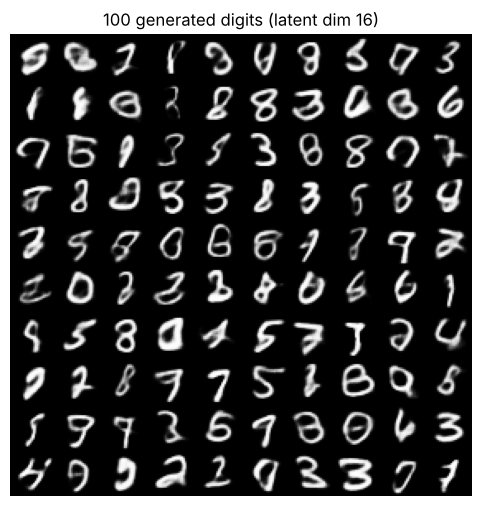

In [6]:
z = tf.random.normal((100, 16), seed=4)
gen = vae16.dec(z).numpy()[..., 0]
grid = np.concatenate([np.concatenate(gen[r * 10:(r + 1) * 10], axis=1) for r in range(10)], axis=0)
plt.figure(figsize=(6, 6)); plt.imshow(grid, cmap="gray"); plt.axis("off"); plt.title("100 generated digits (latent dim 16)"); plt.show()

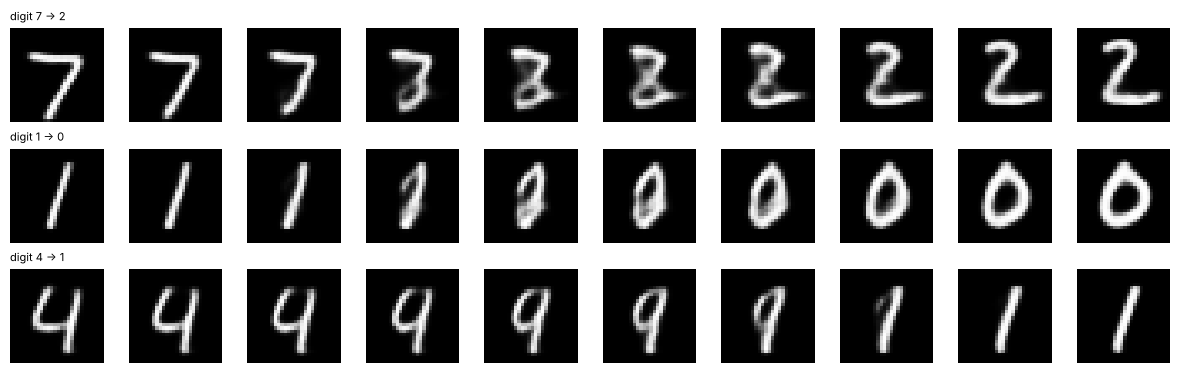

In [7]:
def interp(i, j, steps=10):
    za, zb = vae16.enc(x_test[[i]])[0], vae16.enc(x_test[[j]])[0]
    zs = tf.concat([(1 - a) * za + a * zb for a in np.linspace(0, 1, steps)], 0)
    return vae16.dec(zs).numpy()[..., 0]
pairs = [(0, 1), (2, 3), (4, 5)]
fig, axes = plt.subplots(3, 10, figsize=(12, 3.8))
for r, (i, j) in enumerate(pairs):
    for c, im in enumerate(interp(i, j)):
        axes[r, c].imshow(im, cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(f"digit {y_test[i]} -> {y_test[j]}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 3. A 2-D latent space for visualisation

In [8]:
vae2 = VAE(2); vae2.compile(optimizer=keras.optimizers.Adam(1e-3))
h2 = vae2.fit(x_train, epochs=15, batch_size=128, verbose=2)
print("final loss (2-D latent): %.2f  vs  (16-D latent): %.2f" % (h2.history["loss"][-1], h16.history["loss"][-1]))

Epoch 1/15


469/469 - 34s - 72ms/step - kl: 3.9947 - loss: 200.9043 - recon: 196.9096


Epoch 2/15


469/469 - 32s - 68ms/step - kl: 4.9596 - loss: 166.0773 - recon: 161.1178


Epoch 3/15


469/469 - 37s - 78ms/step - kl: 5.5102 - loss: 157.8461 - recon: 152.3359


... (21 outputs left out)

469/469 - 22s - 48ms/step - kl: 6.4891 - loss: 145.3401 - recon: 138.8509


Epoch 15/15


469/469 - 17s - 36ms/step - kl: 6.5035 - loss: 144.9120 - recon: 138.4085


final loss (2-D latent): 144.91  vs  (16-D latent): 99.31


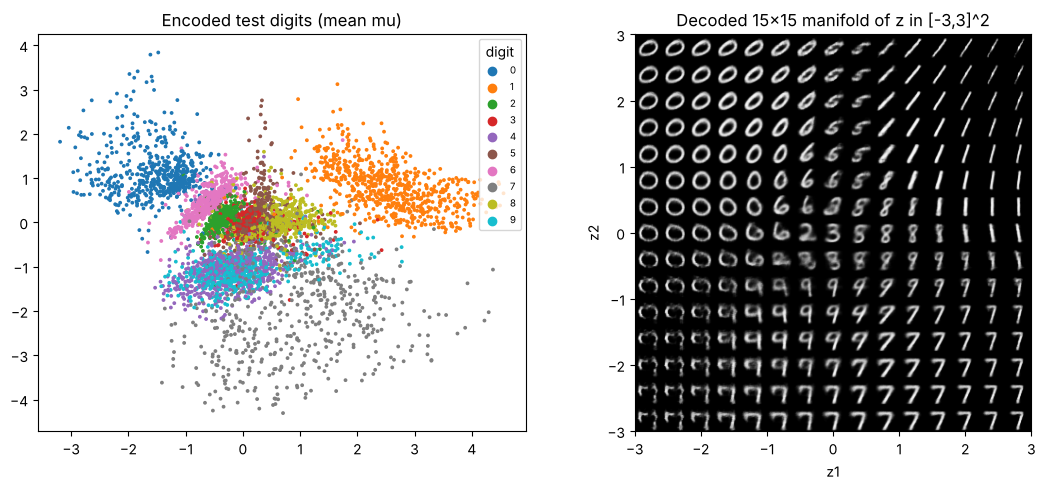

In [9]:
mu2 = vae2.enc.predict(x_test[:6000], verbose=0)[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
sc = ax[0].scatter(mu2[:, 0], mu2[:, 1], c=y_test[:6000], cmap="tab10", s=3)
ax[0].legend(*sc.legend_elements(), title="digit", fontsize=7, loc="upper right"); ax[0].set_title("Encoded test digits (mean mu)")
n = 15; xs = np.linspace(-3, 3, n)
canvas = np.zeros((28 * n, 28 * n))
for i, yv in enumerate(xs[::-1]):
    dec = vae2.dec(np.array([[xv, yv] for xv in xs], dtype="float32")).numpy()[..., 0]
    for j in range(n): canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = dec[j]
ax[1].imshow(canvas, cmap="gray", extent=[-3, 3, -3, 3]); ax[1].set_title("Decoded 15x15 manifold of z in [-3,3]^2")
ax[1].set_xlabel("z1"); ax[1].set_ylabel("z2")
plt.tight_layout(); plt.show()

## 4. Effect of the KL weight (beta-VAE)

beta=0.1   reconstruction loss  68.76   KL  48.16


beta=1.0   reconstruction loss  82.37   KL  21.47


beta=4.0   reconstruction loss 111.18   KL   9.10


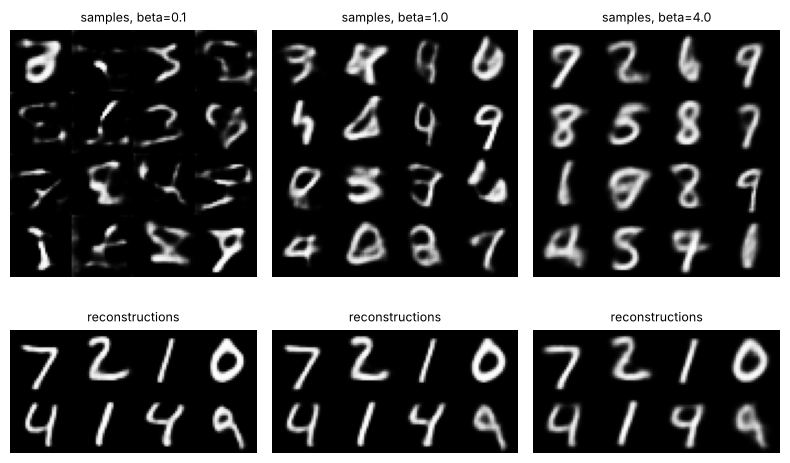

In [10]:
res = {}
for beta in (0.1, 1.0, 4.0):
    m = VAE(16, beta); m.compile(optimizer=keras.optimizers.Adam(1e-3))
    hh = m.fit(x_train, epochs=6, batch_size=128, verbose=0)
    res[beta] = (hh.history["recon"][-1], hh.history["kl"][-1], m)
    print(f"beta={beta:<4}  reconstruction loss {res[beta][0]:6.2f}   KL {res[beta][1]:6.2f}")
fig, axes = plt.subplots(2, 3, figsize=(8, 5.4))
zz = tf.random.normal((16, 16), seed=9)
for c, (beta, (_, _, m)) in enumerate(res.items()):
    g = m.dec(zz).numpy()[..., 0]
    axes[0, c].imshow(np.concatenate([np.concatenate(g[r * 4:(r + 1) * 4], 1) for r in range(4)], 0), cmap="gray")
    axes[0, c].set_title(f"samples, beta={beta}", fontsize=9); axes[0, c].axis("off")
    rr = m.dec(m.enc(x_test[:8])[0]).numpy()[..., 0]
    axes[1, c].imshow(np.concatenate([np.concatenate(rr[:4], 1), np.concatenate(rr[4:], 1)], 0), cmap="gray")
    axes[1, c].set_title("reconstructions", fontsize=9); axes[1, c].axis("off")
plt.tight_layout(); plt.show()